# 03 — Linear baseline: OLS, Ridge and Elastic Net

**Goal:** the simplest regression model for RUL, so every later model (trees, LSTM, TCN) has a bar to beat.

- **Features (v1):** the 3 operating settings + 21 raw sensors at the current cycle. Aryan's engineered features are not merged yet; this notebook is re-run on them later as a separate experiment.
- **Protocol:** `docs/EVALUATION_PROTOCOL.md`: no RUL cap, 80/20 split by engine (seed 42), scored on the 100 validation cut-off rows.
- **Tuning rule:** hyperparameters are chosen by **validation RMSE** (big misses matter most for maintenance). The official test set is scored **once**, at the end, for the chosen model only.

Run this notebook from the `notebooks/` folder.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from rul_prediction.data import SENSOR_COLUMNS, SETTING_COLUMNS, load_cmapss_file, load_rul_file
from rul_prediction.metrics import score_predictions
from rul_prediction.splits import DEFAULT_SEED, sample_cutoff_rows, split_by_engine, split_engine_ids
from rul_prediction.targets import add_train_rul, attach_test_rul, last_observed_rows

RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Target, split and validation points

All three come from the shared modules, so this baseline is scored on exactly the same rows as every other model. The assert checks the 100 points against the committed `docs/fd001_validation_cutoffs.csv`.

In [2]:
train = add_train_rul(load_cmapss_file(RAW_DIR / "train_FD001.txt"))
train_ids, val_ids = split_engine_ids(train["engine_id"])
train_df, val_df = split_by_engine(train, val_ids)
val_points = sample_cutoff_rows(val_df)

expected_points = pd.read_csv(PROJECT_ROOT / "docs" / "fd001_validation_cutoffs.csv")
pd.testing.assert_frame_equal(val_points[["engine_id", "cycle", "rul"]], expected_points)

FEATURES = SETTING_COLUMNS + SENSOR_COLUMNS
FEATURE_SET_NAME = "raw settings + sensors (24)"

print(f"train engines: {len(train_ids)}, rows: {len(train_df)}")
print(f"validation engines: {len(val_ids)}, rows: {len(val_df)}, cut-off points: {len(val_points)}")
print(f"features: {len(FEATURES)}")

train engines: 80, rows: 16390
validation engines: 20, rows: 4241, cut-off points: 100
features: 24


## 2. Models

| Model | Fits | Hyperparameter |
|---|---|---|
| **OLS** (`LinearRegression`) | Minimises squared error only | none |
| **Ridge** | Squared error + alpha × sum of squared coefficients (L2) | `alpha`: bigger = coefficients shrunk harder towards 0 |
| **Elastic Net** | Squared error + mix of L1 (sum of absolute coefficients) and L2 | `alpha` (strength), `l1_ratio` (share of L1; L1 can set coefficients exactly to 0) |

**Why scale first:** the penalty compares coefficient sizes, so features must be on the same scale or the penalty would unfairly hit sensors measured in small units. The scaler sits inside the pipeline, so `fit` learns the mean/std from the 80 training engines only.

Grids are kept small on purpose: we tune on one fixed validation split, and a big grid would overfit it.

In [3]:
RIDGE_ALPHAS = [0.01, 0.1, 1, 10, 100, 1000]
ELASTIC_NET_ALPHAS = [0.001, 0.01, 0.1, 1]
ELASTIC_NET_L1_RATIOS = [0.2, 0.5, 0.8]

candidates = [("OLS", {}, LinearRegression())]
candidates += [("Ridge", {"alpha": a}, Ridge(alpha=a)) for a in RIDGE_ALPHAS]
candidates += [
    ("ElasticNet", {"alpha": a, "l1_ratio": r}, ElasticNet(alpha=a, l1_ratio=r, max_iter=50_000))
    for a in ELASTIC_NET_ALPHAS
    for r in ELASTIC_NET_L1_RATIOS
]


def fit_on_train_engines(model):
    """Scaler + model, fitted on the 80 training engines only."""
    return make_pipeline(StandardScaler(), model).fit(train_df[FEATURES], train_df["rul"])


rows, fitted = [], {}
for name, params, model in candidates:
    pipeline = fit_on_train_engines(model)
    cutoff = score_predictions(val_points["rul"], pipeline.predict(val_points[FEATURES]))
    all_rows = score_predictions(val_df["rul"], pipeline.predict(val_df[FEATURES]))
    key = (name, tuple(sorted(params.items())))
    fitted[key] = pipeline
    rows.append({
        "model": name,
        "params": params,
        "val_mae": cutoff["mae"],
        "val_rmse": cutoff["rmse"],
        "val_n": cutoff["n"],
        "val_all_rows_mae": all_rows["mae"],
        "val_all_rows_rmse": all_rows["rmse"],
    })

grid = pd.DataFrame(rows)
grid.round(2).sort_values("val_rmse")

,model,params,val_mae,val_rmse,val_n,val_all_rows_mae,val_all_rows_rmse
0,OLS,{},32.86,42.92,100,36.36,49.72
12,ElasticNet,"{'alpha': 0.01, 'l1_ratio': 0.8}",32.87,42.92,100,36.36,49.72
8,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.5}",32.87,42.92,100,36.36,49.72
7,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.2}",32.87,42.92,100,36.36,49.72
9,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.8}",32.87,42.92,100,36.36,49.72
3,Ridge,{'alpha': 1},32.87,42.92,100,36.36,49.72
2,Ridge,{'alpha': 0.1},32.86,42.92,100,36.36,49.72
1,Ridge,{'alpha': 0.01},32.86,42.92,100,36.36,49.72
4,Ridge,{'alpha': 10},32.87,42.92,100,36.36,49.72
5,Ridge,{'alpha': 100},32.88,42.93,100,36.36,49.72


## 3. Choose the model on validation only

Best setting per model family by validation RMSE, then the overall winner. This choice is final before the test set is touched.

In [4]:
best_per_family = grid.loc[grid.groupby("model")["val_rmse"].idxmin()].sort_values("val_rmse")
chosen = best_per_family.iloc[0]
chosen_pipeline = fitted[(chosen["model"], tuple(sorted(chosen["params"].items())))]

model_label = chosen["model"] + (f" {chosen['params']}" if chosen["params"] else "")
print("chosen:", model_label)
best_per_family.round(2)

chosen: OLS


,model,params,val_mae,val_rmse,val_n,val_all_rows_mae,val_all_rows_rmse
0,OLS,{},32.86,42.92,100,36.36,49.72
1,Ridge,{'alpha': 0.01},32.86,42.92,100,36.36,49.72
9,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.8}",32.87,42.92,100,36.36,49.72


## 4. What regularization does to the coefficients

Ridge coefficient path: each line is one feature's coefficient (on scaled features) as `alpha` grows. At small `alpha` Ridge equals OLS; as `alpha` grows, coefficients shrink overall. With correlated sensors the paths are not monotonic: some coefficients first grow while their correlated partners shrink. Fitted on training engines only. The grey band is the alpha range tried in the tuning grid.

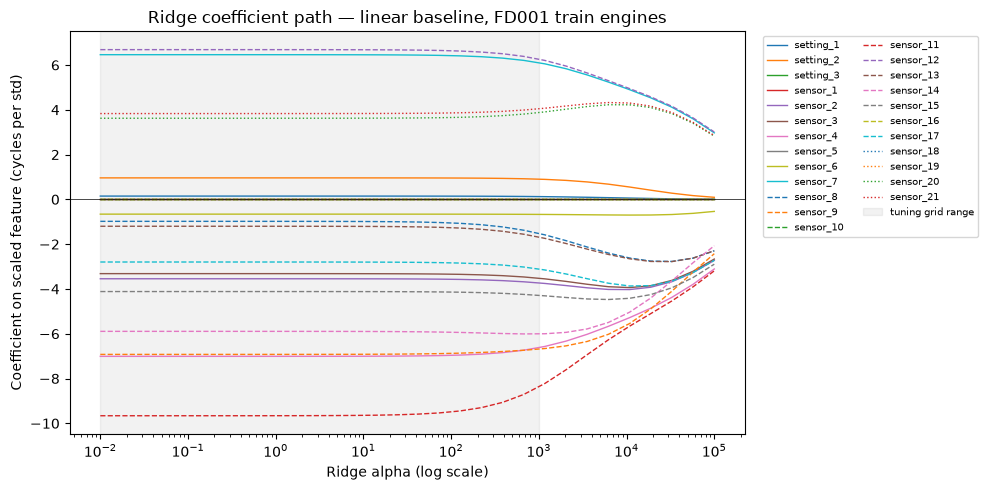

In [5]:
path_alphas = np.logspace(-2, 5, 30)
path = pd.DataFrame(
    [fit_on_train_engines(Ridge(alpha=a))[-1].coef_ for a in path_alphas],
    index=path_alphas,
    columns=FEATURES,
)

fig, ax = plt.subplots(figsize=(10, 5))
line_styles = ["-", "--", ":"]
for i, feature in enumerate(path.columns):
    ax.plot(path.index, path[feature], linewidth=1, linestyle=line_styles[i // 10], label=feature)
ax.axvspan(min(RIDGE_ALPHAS), max(RIDGE_ALPHAS), color="grey", alpha=0.1, label="tuning grid range")
ax.set_xscale("log")
ax.set_xlabel("Ridge alpha (log scale)")
ax.set_ylabel("Coefficient on scaled feature (cycles per std)")
ax.set_title("Ridge coefficient path — linear baseline, FD001 train engines")
ax.axhline(0, color="black", linewidth=0.5)
ax.legend(fontsize=7, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_ridge_coefficient_path.png", dpi=150)
plt.show()

In [6]:
coefficients = pd.DataFrame({
    family: fitted[(family, tuple(sorted(row["params"].items())))][-1].coef_
    for family, row in best_per_family.set_index("model").iterrows()
}, index=FEATURES)

# A sensor that never changes carries no information: after scaling it is all
# zeros, so every model gives it a ~0 coefficient. That is not regularization.
constant_in_train = [f for f in FEATURES if train_df[f].nunique() == 1]
print("constant in training engines:", constant_in_train)

# Demo only (not a tuning candidate): a strong L1 penalty sets extra
# coefficients exactly to 0, which is how Elastic Net / Lasso select features.
coefficients["ElasticNet a=1, l1=0.8 (demo)"] = fit_on_train_engines(
    ElasticNet(alpha=1, l1_ratio=0.8, max_iter=50_000)
)[-1].coef_

near_zero = (coefficients.abs() < 1e-6).sum()
print("coefficients ~0 (|coef| < 1e-6):", near_zero.to_dict())
coefficients.round(2)

constant in training engines: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
coefficients ~0 (|coef| < 1e-6): {'OLS': 7, 'Ridge': 7, 'ElasticNet': 7, 'ElasticNet a=1, l1=0.8 (demo)': 8}


,OLS,Ridge,ElasticNet,"ElasticNet a=1, l1=0.8 (demo)"
setting_1,0.15,0.15,0.15,0.00
setting_2,0.96,0.96,0.96,0.11
setting_3,0.00,0.00,0.00,0.00
sensor_1,0.00,0.00,0.00,0.00
sensor_2,-3.54,-3.54,-3.55,-3.86
sensor_3,-3.32,-3.32,-3.32,-3.68
sensor_4,-7.01,-7.01,-7.01,-6.16
sensor_5,-0.00,0.00,0.00,0.00
sensor_6,-0.66,-0.66,-0.66,-0.12
sensor_7,6.46,6.46,6.46,5.60


## 4b. Underfitting or overfitting? Train vs validation error

If the model **overfits** (high variance), training error is much lower than validation error, and regularization should help. If it **underfits** (high bias), both errors are high and close. Compared on all rows, because the cut-off points exist only for validation engines.

In [7]:
fit_check = pd.DataFrame({
    "train (80 engines, all rows)": score_predictions(train_df["rul"], chosen_pipeline.predict(train_df[FEATURES])),
    "validation (20 engines, all rows)": score_predictions(val_df["rul"], chosen_pipeline.predict(val_df[FEATURES])),
}).T
fit_check.round(2)

,mae,rmse,n
"train (80 engines, all rows)",33.33,43.31,16390.0
"validation (20 engines, all rows)",36.36,49.72,4241.0


## 4c. Multicollinearity between sensors

Correlated inputs make individual linear coefficients unstable and hard to interpret (an assumption check from the concept map). Pearson correlation on the training engines, constant features excluded.

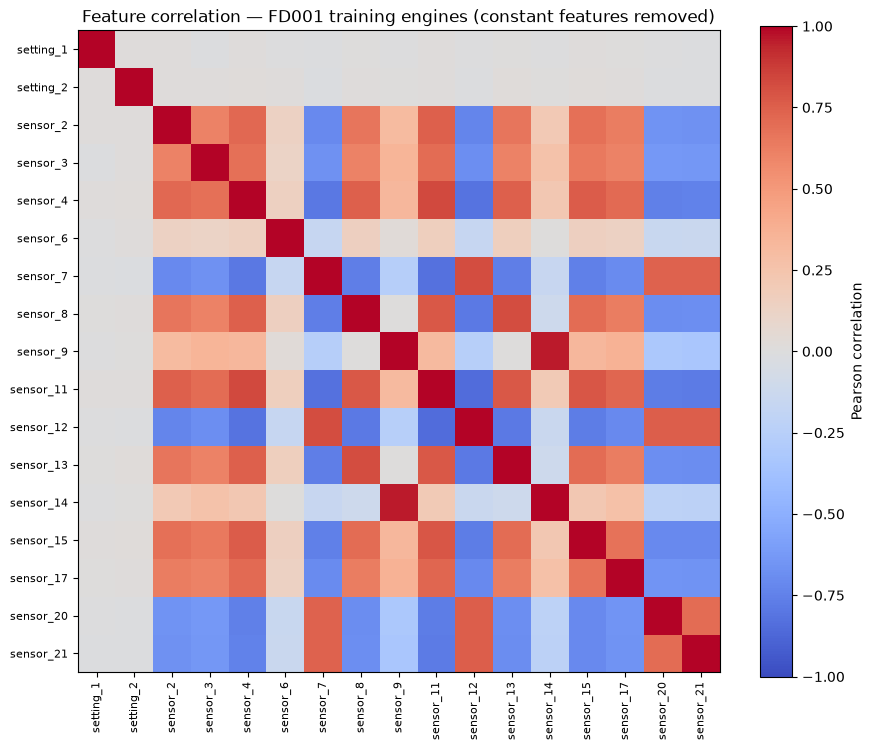

feature pairs with |correlation| >= 0.8: 7


,,correlation
sensor_9,sensor_14,0.96
sensor_11,sensor_12,-0.85
sensor_4,sensor_11,0.83
sensor_7,sensor_11,-0.82
sensor_8,sensor_13,0.82
sensor_4,sensor_12,-0.82
sensor_7,sensor_12,0.82


In [8]:
informative = [f for f in FEATURES if f not in constant_in_train]
correlation = train_df[informative].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(informative)), informative, rotation=90, fontsize=8)
ax.set_yticks(range(len(informative)), informative, fontsize=8)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Feature correlation — FD001 training engines (constant features removed)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_feature_correlation.png", dpi=150)
plt.show()

pairs = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), k=1)).stack()
strong_pairs = pairs[pairs.abs() >= 0.8].sort_values(key=abs, ascending=False)
print(f"feature pairs with |correlation| >= 0.8: {len(strong_pairs)}")
strong_pairs.round(2).to_frame("correlation")

## 4d. Does a single sensor reading tell early life apart?

The sensor with the largest coefficient, plotted against true RUL for all training rows. If its values are flat for large RUL, a model using only the current reading cannot separate RUL 200 from RUL 300.

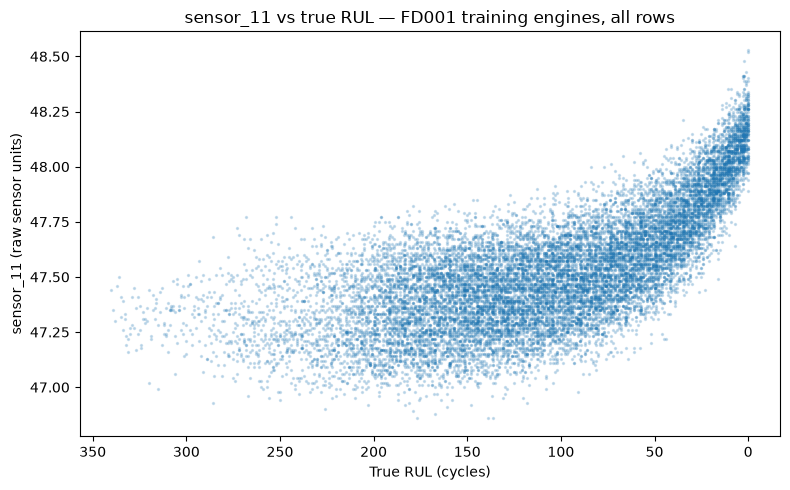

largest |OLS coefficient|: sensor_11


In [9]:
top_sensor = coefficients["OLS"].abs().idxmax()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train_df["rul"], train_df[top_sensor], s=2, alpha=0.2)
ax.set_xlabel("True RUL (cycles)")
ax.set_ylabel(f"{top_sensor} (raw sensor units)")
ax.set_title(f"{top_sensor} vs true RUL — FD001 training engines, all rows")
ax.invert_xaxis()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_top_sensor_vs_rul.png", dpi=150)
plt.show()

print("largest |OLS coefficient|:", top_sensor)

## 5. Diagnostics on validation (chosen model)

Checks from the concept map's *assumptions of linear regression*:

- **Predicted vs actual:** points on the diagonal = perfect.
- **Residuals vs predicted:** a curve means the relationship is not linear; a funnel means non-constant variance.
- **Residual histogram and Q-Q plot:** how far residuals are from normal.

Residual = actual RUL − predicted RUL (positive = model said the engine fails sooner than it does).

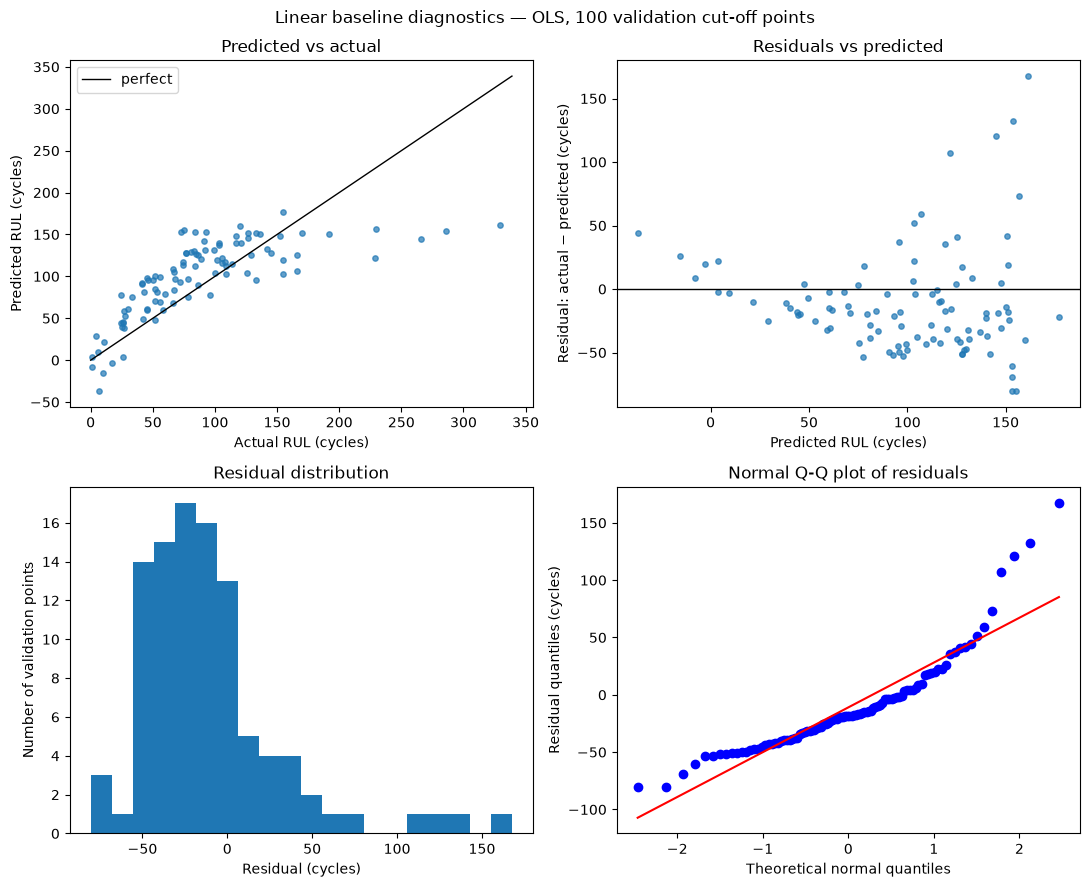

negative RUL predictions: 4 of 100


In [10]:
val_pred = chosen_pipeline.predict(val_points[FEATURES])
residuals = val_points["rul"] - val_pred

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

limit = max(val_points["rul"].max(), val_pred.max()) + 10
axes[0, 0].scatter(val_points["rul"], val_pred, s=15, alpha=0.7)
axes[0, 0].plot([0, limit], [0, limit], color="black", linewidth=1, label="perfect")
axes[0, 0].set_xlabel("Actual RUL (cycles)")
axes[0, 0].set_ylabel("Predicted RUL (cycles)")
axes[0, 0].set_title("Predicted vs actual")
axes[0, 0].legend()

axes[0, 1].scatter(val_pred, residuals, s=15, alpha=0.7)
axes[0, 1].axhline(0, color="black", linewidth=1)
axes[0, 1].set_xlabel("Predicted RUL (cycles)")
axes[0, 1].set_ylabel("Residual: actual − predicted (cycles)")
axes[0, 1].set_title("Residuals vs predicted")

axes[1, 0].hist(residuals, bins=20)
axes[1, 0].set_xlabel("Residual (cycles)")
axes[1, 0].set_ylabel("Number of validation points")
axes[1, 0].set_title("Residual distribution")

stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q plot of residuals")
axes[1, 1].set_xlabel("Theoretical normal quantiles")
axes[1, 1].set_ylabel("Residual quantiles (cycles)")

fig.suptitle(f"Linear baseline diagnostics — {model_label}, 100 validation cut-off points")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_baseline_validation_diagnostics.png", dpi=150)
plt.show()

print(f"negative RUL predictions: {(val_pred < 0).sum()} of {len(val_pred)}")

## 6. Final test evaluation (run once)

The chosen model above is fixed. Each test engine is predicted at its last observed cycle and joined to `RUL_FD001.txt` by `engine_id`. Do not change the model after reading this number.

In [11]:
test_points = attach_test_rul(
    last_observed_rows(load_cmapss_file(RAW_DIR / "test_FD001.txt")),
    load_rul_file(RAW_DIR / "RUL_FD001.txt"),
)
test_scores = score_predictions(test_points["rul"], chosen_pipeline.predict(test_points[FEATURES]))
test_scores

{'mae': 24.90804124211765, 'rmse': 31.173574270157086, 'n': 100}

## 7. Save results

Everything below is written from the variables above, so no number is typed by hand.

In [12]:
split_description = f"engine ID 80/20, seed {DEFAULT_SEED}, 100 val cut-offs (docs/fd001_validation_cutoffs.csv)"

summary = best_per_family.assign(
    features=FEATURE_SET_NAME,
    target="RUL = last cycle - cycle, no cap",
    split=split_description,
    test_mae=np.nan,
    test_rmse=np.nan,
    test_n=np.nan,
)
is_chosen = summary["model"] == chosen["model"]
summary.loc[is_chosen, ["test_mae", "test_rmse", "test_n"]] = [
    test_scores["mae"], test_scores["rmse"], test_scores["n"]
]

grid.to_csv(RESULTS_DIR / "linear_baseline_grid.csv", index=False)
summary.to_csv(RESULTS_DIR / "linear_baseline_results.csv", index=False)

log = f"""# Experiment log — linear baseline v1 (raw sensors)

- **Owner:** Abhayanth
- **Notebook:** notebooks/03_linear_baseline.ipynb
- **Question:** How well does a linear model on raw settings + sensors predict RUL, and does regularization help?
- **Dataset/subset:** FD001
- **Split protocol / engine IDs:** {split_description}; validation engines {val_ids}
- **Target settings (including any RUL cap):** RUL = last cycle - cycle, no cap
- **Features or window length:** {FEATURE_SET_NAME}: {", ".join(FEATURES)}
- **Model:** StandardScaler + {chosen["model"]} (chosen by validation RMSE among OLS, Ridge, ElasticNet)
- **Hyperparameters:** {chosen["params"]}; grids: Ridge alpha {RIDGE_ALPHAS}, ElasticNet alpha {ELASTIC_NET_ALPHAS} x l1_ratio {ELASTIC_NET_L1_RATIOS}
- **Random seed:** {DEFAULT_SEED} (split and cut-offs; models are deterministic)
- **Other settings:** StandardScaler defaults (mean/std from training engines); ElasticNet max_iter=50000; scikit-learn {sklearn.__version__}, scipy {scipy.__version__}, pandas {pd.__version__}, numpy {np.__version__}
- **Validation MAE / RMSE (cycles, 100 cut-offs):** {chosen["val_mae"]:.2f} / {chosen["val_rmse"]:.2f}
- **Test MAE / RMSE (cycles, 100 engines, run once):** {test_scores["mae"]:.2f} / {test_scores["rmse"]:.2f}
- **Plots/results file:** reports/figures/linear_ridge_coefficient_path.png, reports/figures/linear_baseline_validation_diagnostics.png, reports/results/linear_baseline_results.csv, reports/results/linear_baseline_grid.csv
- **What changed from previous experiment:** first model
- **Interpretation:** see the Findings section of the notebook
- **Limitations / next experiment:** re-run on Aryan's engineered features; RUL cap only as a separate logged experiment
"""
(RESULTS_DIR / "linear_baseline_experiment_log.md").write_text(log)
summary.round(2)

,model,params,val_mae,val_rmse,val_n,val_all_rows_mae,val_all_rows_rmse,features,target,split,test_mae,test_rmse,test_n
0,OLS,{},32.86,42.92,100,36.36,49.72,raw settings + sensors (24),"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",24.91,31.17,100.0
1,Ridge,{'alpha': 0.01},32.86,42.92,100,36.36,49.72,raw settings + sensors (24),"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",NaN,NaN,NaN
9,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.8}",32.87,42.92,100,36.36,49.72,raw settings + sensors (24),"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",NaN,NaN,NaN


## Findings

_All numbers come from the cell outputs above. Validation = the 100 shared cut-off points unless stated otherwise._

**1. Baseline score.** OLS on the 24 raw settings and sensors scores validation **MAE 32.86, RMSE 42.92** cycles. On all 4,241 validation rows it scores MAE 36.36, RMSE 49.72. This is the bar the tree and sequence models must beat.

**2. Regularization gives no measurable gain.**
- The best Ridge (alpha 0.01) and Elastic Net (alpha 0.001, l1_ratio 0.8) settings match OLS to two decimals (RMSE 42.92). OLS "won" by a negligible margin, so treat this as a tie. OLS is kept as the simplest model.
- The largest grid difference is about 0.6 cycles RMSE. Validation has only about 20 independent engines, so differences this small are within noise.
- Why regularization has nothing to fix: training error (RMSE 43.31 on all rows of the 80 training engines) is almost as high as validation error (49.72). The model is **underfitting** (high bias), not overfitting (high variance).
- Regularization reduces variance, so it can't help a model that is too simple. That fits 16,390 rows for 24 features.

**3. Seven features carry no information.** `setting_3`, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19` never change across the training engines, so every model gives them a ~0 coefficient. That is not regularization. With a strong L1 penalty (demo, alpha 1), Elastic Net also zeroes `setting_1`, which shows how L1 does feature selection. Formal feature selection belongs to Aryan's notebook.

**4. Multicollinearity.**
- 7 pairs of training features have |correlation| ≥ 0.8. The strongest is `sensor_9`–`sensor_14` at 0.96, and `sensor_11` and `sensor_12` both correlate with several others.
- Individual coefficients therefore should not be read as "this sensor's effect".
- It also explains why the Ridge paths are not monotonic: correlated coefficients trade weight as alpha grows.

**5. Diagnostics (validation plots) show the linear model's limits:**
- *Non-linearity:* predictions flatten at about 150 cycles. Engines with actual RUL of 200–330 are all predicted around 120–160. Residuals are mostly negative for predictions of 50–150, meaning over-prediction.
- *Heavy tail:* the Q-Q plot's right tail comes from the large-RUL points the model misses. Normality isn't needed for point predictions, but it signals the misfit.
- *Not checked:* independence. The 5 cut-offs of one engine are correlated by design.
- *Supporting evidence:* `sensor_11`, the largest coefficient, is flat and noisy for RUL above about 150 and curves only near failure. A single current-cycle reading can't separate RUL 200 from RUL 300, which matches the flattening.

**6. Impossible outputs.** 4 of 100 validation predictions are negative RUL. They are left as-is: clipping changes the model, so it would be a separate logged experiment.

**7. Test set (scored once, after OLS was chosen on validation):** **MAE 24.91, RMSE 31.17** cycles on 100 test engines. This is lower than validation. A plausible but unconfirmed reason is that the validation cut-offs include very large RUL values (up to about 330) that this model misses. The protocol forbids summarising test RUL values, so it can't be checked here. Re-running this notebook re-scores the same fixed model, so the test number is only valid while nothing above changes.

**Next:**
- Re-run with Aryan's engineered (rolling) features as experiment v2 on the same split. Trend features give the model information a single reading lacks.
- A RUL cap, which the flattening suggests, is a team decision to log as its own experiment.